# PitchFlower F0 ratio editor — PyCharm-compatible Bokeh version

This notebook keeps the original F0 contour read-only and edits pitch through a separate **ratio-control curve** underneath it.

This version intentionally uses **raw Bokeh for the editable plots** instead of HoloViews `CurveEdit`. PyCharm notebooks require the `jupyter_bokeh`/ipywidgets communication path for full Bokeh↔Python synchronization, and using Bokeh directly avoids the blank editable glyph issue seen with linked HoloViews streams in the IDE.

Workflow:

1. Load audio and compute the original WORLD F0.
2. Drag pre-created ratio points every 10 ms in the lower Bokeh editor.
3. Convert those points into a dense smoothed spline with SciPy.
4. Multiply the original voiced F0 by that ratio curve; unvoiced frames remain zero.
5. Save the control-point group plus dense target arrays.
6. Synthesize the edited audio with PitchFlower.
7. Listen to the original, edited output, and a stereo A/B stream with **original on the left** and **edited on the right**.


## Dependencies

For PyCharm's notebook frontend, install `jupyter_bokeh` and `ipywidgets` in the **same uv environment as this kernel**:

```bash
uv add panel bokeh scipy jupyter-bokeh ipywidgets
```

The PitchFlower environment should already contain PyTorch, torchaudio, WORLD, Vocos, and PitchFlower.

After installing `jupyter-bokeh`, **restart the notebook kernel** before running this notebook. This matters because PyCharm uses the `jupyter_bokeh` ipywidget transport for bidirectional Bokeh/Panel interaction.


In [1]:
from pathlib import Path
import importlib.util

import numpy as np
import pyworld as pw

import torch
import torchaudio

from pitchflower.synthesizer import PitchFlowerSynthesizer
from vocos import Vocos

import panel as pn
from bokeh.plotting import figure
from bokeh.models import (
    ColumnDataSource,
    PointDrawTool,
    HoverTool,
    Span,
    Range1d,
)
from scipy.interpolate import UnivariateSpline

import IPython.display as ipd
import matplotlib.pyplot as plt

# PyCharm notebooks need jupyter_bokeh for fully bidirectional Bokeh/Panel
# interaction. Fail early with a useful message instead of silently drawing
# a non-interactive/partially rendered editor.
if importlib.util.find_spec("jupyter_bokeh") is None:
    raise RuntimeError(
        "jupyter_bokeh is not installed in this notebook kernel. "
        "Run: uv add jupyter-bokeh ipywidgets  then restart the kernel."
    )

# Force Panel to render through the ipywidgets transport. This is the
# important PyCharm compatibility setting.
pn.extension(comms="ipywidgets")

print("Panel comms:", pn.config.comms)
print("jupyter_bokeh: available")


/home/bennie/PycharmProjects/PitchFlower/.venv/lib/python3.13/site-packages/pyworld/__init__.py:13: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


Panel comms: ipywidgets
jupyter_bokeh: available


In [2]:
# -----------------------------
# Global configuration
# -----------------------------

SAMPLE_RATE = 24_000
WORLD_FRAME_PERIOD_MS = 32 / 3
WORLD_F0_FLOOR = 20

# Keep the same initial target as the original notebook: -6 semitones.
# Change to 0.0 if you want the editor to start at ratio 1.0.
INITIAL_SEMITONE_SHIFT = -6.0
DEFAULT_RATIO = 2.0 ** (INITIAL_SEMITONE_SHIFT / 12.0)

# Create a visible/editable pitch-ratio control point every 10 ms.
# WORLD/PitchFlower F0 frames are ~10.667 ms apart, so these control
# points are represented at fractional F0-frame positions and the spline
# is sampled back onto the model/F0 frame grid.
CONTROL_POINT_SPACING_MS = 10.0

# Visible/editable ratio range in the lower plot.
RATIO_MIN = 0.35
RATIO_MAX = 1.65

# The sample is several seconds long, so 100 objects was too low for
# 10-ms default points. Keep the cap comfortably above the expected count.
MAX_CONTROL_POINTS = 10_000

# Input sample and output locations.
AUDIO_PATH = Path("data/13111726-1277332.mp3")
AUDIO_MAX_SAMPLES = 36096 * 3
EDIT_OUTPUT_DIR = Path("data/f0_edits")
EDIT_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# PitchFlower flow-reconstruction settings.
FLOW_STEPS = 10
FLOW_GUIDANCE = 3.0


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
print("Initial ratio:", DEFAULT_RATIO)
print("Default control-point spacing (ms):", CONTROL_POINT_SPACING_MS)
print("Output directory:", EDIT_OUTPUT_DIR)


Device: cuda
Initial ratio: 0.7071067811865476
Default control-point spacing (ms): 10.0
Output directory: data/f0_edits


## Load PitchFlower and Vocos

In [3]:
# If Hugging Face progress bars cause trouble, uncomment these two lines:
# from huggingface_hub.utils import disable_progress_bars
# disable_progress_bars()

synth = PitchFlowerSynthesizer.from_pretrained(
    "diegotg343/PitchFlower"
).to(device)

vocos = Vocos.from_pretrained(
    "charactr/vocos-mel-24khz"
).to(device)

## WORLD F0 helper

In [4]:
def get_f0(audio_1d, sample_rate=SAMPLE_RATE):
    """Return WORLD F0 for a mono waveform as a NumPy array."""
    audio_1d = np.asarray(audio_1d, dtype=np.float64)

    raw_f0, t = pw.harvest(
        audio_1d,
        fs=sample_rate,
        frame_period=WORLD_FRAME_PERIOD_MS,
        f0_floor=WORLD_F0_FLOOR,
    )

    return pw.stonemask(
        audio_1d,
        raw_f0,
        t,
        fs=sample_rate,
    )

## Load and resample the source audio

In [5]:
og_wav, sr = torchaudio.load(AUDIO_PATH)

if sr != SAMPLE_RATE:
    og_wav = torchaudio.transforms.Resample(
        orig_freq=sr,
        new_freq=SAMPLE_RATE,
    )(og_wav)

# Keep the original notebook's intended sample limit, but slice the time axis.
og_wav = og_wav[:, :AUDIO_MAX_SAMPLES]

# PitchFlower expects the audio tensor; WORLD below uses one mono channel.
print("Source shape:", tuple(og_wav.shape))
print("Duration (s):", og_wav.shape[-1] / SAMPLE_RATE)

Source shape: (1, 36075)
Duration (s): 1.503125


/home/bennie/PycharmProjects/PitchFlower/.venv/lib/python3.13/site-packages/torchaudio/_backend/utils.py:213: UserWarning: In 2.9, this function's implementation will be changed to use torchaudio.load_with_torchcodec` under the hood. Some parameters like ``normalize``, ``format``, ``buffer_size``, and ``backend`` will be ignored. We recommend that you port your code to rely directly on TorchCodec's decoder instead: https://docs.pytorch.org/torchcodec/stable/generated/torchcodec.decoders.AudioDecoder.html#torchcodec.decoders.AudioDecoder.
  warnings.warn(


## Compute the original F0 safely

In [6]:
f0 = get_f0(og_wav[0].detach().cpu().numpy())
f0_np = np.asarray(f0, dtype=np.float64)

n_f0_frames = len(f0_np)
f0_frames = np.arange(n_f0_frames, dtype=np.float64)
voiced_mask = f0_np > 0.0

# Avoid np.where(log2(...)) because NumPy evaluates log2(0) before masking.
base_log_f0_np = np.zeros_like(f0_np, dtype=np.float64)
base_log_f0_np[voiced_mask] = np.log2(f0_np[voiced_mask])

log_f0 = torch.tensor(base_log_f0_np, dtype=torch.float32)

print("F0 frames:", n_f0_frames)
print("Voiced frames:", int(voiced_mask.sum()))

F0 frames: 141
Voiced frames: 85


## Encode the source audio once

The encoded `codes` can be reused after you edit the ratio points, so the expensive analysis step does not need to be repeated for every pitch edit.

In [7]:
with torch.inference_mode():
    codes = synth.analyze_audios(og_wav.to(device))

## Interactive ratio editor

The F0 data are already correct; the previous blank lower panels were a frontend/rendering problem. This version removes HoloViews linked-stream editing from the critical path and uses Bokeh's native `ColumnDataSource` + `PointDrawTool`.

- A visible movable point is created every **10 ms**.
- The blue point-draw tool starts active.
- Drag the points vertically to change the local F0 multiplier.
- The line joins all control points, so you can see the control contour directly.
- The smoothed SciPy spline is shown underneath.
- The upper F0 preview updates from the same data.
- `1.0` = unchanged pitch; `0.5` = one octave down; `2.0` = one octave up.

The editor is wrapped with `pn.ipywidget(...)`, which is the supported route for interactive Panel/Bokeh output in PyCharm notebooks.


In [8]:
# ============================================================
# Interactive ratio editor — raw Bokeh + Panel + SciPy
# ============================================================


def make_default_control_points(spacing_ms=CONTROL_POINT_SPACING_MS):
    """Create one ratio-control point every `spacing_ms`."""
    duration_ms = float(n_f0_frames - 1) * WORLD_FRAME_PERIOD_MS

    control_times_ms = np.arange(
        0.0,
        duration_ms + 1e-9,
        float(spacing_ms),
        dtype=np.float64,
    )

    if len(control_times_ms) == 0:
        control_times_ms = np.array([0.0], dtype=np.float64)

    if control_times_ms[-1] < duration_ms - 1e-9:
        control_times_ms = np.append(control_times_ms, duration_ms)

    control_frames = control_times_ms / WORLD_FRAME_PERIOD_MS
    control_ratios = np.full(
        control_frames.shape,
        DEFAULT_RATIO,
        dtype=np.float64,
    )

    return control_frames, control_ratios


initial_control_x, initial_control_ratio = make_default_control_points()

print(
    f"Created {len(initial_control_x)} visible control points "
    f"at {CONTROL_POINT_SPACING_MS:g} ms spacing"
)


# ------------------------------------------------------------
# Single source of truth for the editable control points.
# Both the visible line and visible points use this SAME source,
# so moving a point immediately moves the line in the browser.
# ------------------------------------------------------------

control_source = ColumnDataSource(
    data={
        "frame": initial_control_x.tolist(),
        "ratio": initial_control_ratio.tolist(),
    }
)


smoothing_slider = pn.widgets.FloatSlider(
    name="Spline smoothing",
    start=0.0,
    end=1.0,
    step=0.01,
    value=0.05,
    width=360,
)

reset_button = pn.widgets.Button(
    name="Reset 10 ms grid",
    button_type="default",
    width=150,
)

refresh_button = pn.widgets.Button(
    name="Refresh previews",
    button_type="primary",
    width=150,
)

status_pane = pn.pane.Markdown("")


def clean_control_points(data=None):
    """Return sorted finite (frame, ratio) arrays from the Bokeh source."""
    if data is None:
        data = control_source.data

    x = np.asarray(data.get("frame", []), dtype=np.float64)
    y = np.asarray(data.get("ratio", []), dtype=np.float64)

    valid = np.isfinite(x) & np.isfinite(y)
    x = x[valid]
    y = y[valid]

    if len(x) == 0:
        return make_default_control_points()

    x = np.clip(x, 0.0, float(n_f0_frames - 1))
    y = np.clip(y, RATIO_MIN, RATIO_MAX)

    order = np.argsort(x)
    x = x[order]
    y = y[order]

    # Remove exact/near-duplicate x positions so SciPy always gets
    # a strictly increasing x vector.
    keep_x = []
    keep_y = []
    for xi, yi in zip(x, y):
        xi = float(np.round(xi, 6))
        yi = float(yi)
        if keep_x and abs(xi - keep_x[-1]) < 1e-6:
            keep_y[-1] = yi
        else:
            keep_x.append(xi)
            keep_y.append(yi)

    return (
        np.asarray(keep_x, dtype=np.float64),
        np.asarray(keep_y, dtype=np.float64),
    )


def build_ratio_curve(data=None, smoothing=None):
    """Convert control points into one smoothed ratio per WORLD F0 frame."""
    if smoothing is None:
        smoothing = smoothing_slider.value

    x, y = clean_control_points(data)

    if len(x) == 0:
        return np.full(n_f0_frames, DEFAULT_RATIO, dtype=np.float64)

    if len(x) == 1:
        return np.full(n_f0_frames, y[0], dtype=np.float64)

    k = min(3, len(x) - 1)

    ratio_scale = max(float(np.ptp(y)), 0.05)
    scipy_s = float(smoothing) * len(x) * ratio_scale**2

    spline = UnivariateSpline(
        x,
        y,
        k=k,
        s=scipy_s,
        ext=3,
    )

    dense_ratio = spline(f0_frames)
    return np.clip(dense_ratio, RATIO_MIN, RATIO_MAX)


def get_current_pitch_edit(data=None, smoothing=None):
    """Return dense ratio, target F0 Hz, and PitchFlower log2-F0 arrays."""
    if data is None:
        data = control_source.data

    if smoothing is None:
        smoothing = smoothing_slider.value

    ratio_curve = build_ratio_curve(data, smoothing)

    target_f0_np = np.zeros_like(f0_np, dtype=np.float64)
    target_f0_np[voiced_mask] = (
        f0_np[voiced_mask] * ratio_curve[voiced_mask]
    )

    target_log_f0_np = np.zeros_like(base_log_f0_np, dtype=np.float64)
    target_log_f0_np[voiced_mask] = (
        base_log_f0_np[voiced_mask]
        + np.log2(ratio_curve[voiced_mask])
    )

    return {
        "ratio": ratio_curve,
        "target_f0": target_f0_np,
        "target_log_f0": target_log_f0_np,
    }


# ============================================================
# Bokeh figures
# ============================================================

initial_state = get_current_pitch_edit()

# -----------------------------
# Read-only F0 preview
# -----------------------------

f0_preview_source = ColumnDataSource(
    data={
        "frame": f0_frames.tolist(),
        "gt": f0_np.tolist(),
        "target": initial_state["target_f0"].tolist(),
    }
)

voiced_max = float(f0_np[voiced_mask].max()) if voiced_mask.any() else 150.0
f0_top = max(150.0, voiced_max * max(1.15, RATIO_MAX * 1.05))

f0_plot = figure(
    width=950,
    height=350,
    x_range=Range1d(0, max(1, n_f0_frames - 1)),
    y_range=Range1d(0, f0_top),
    title="F0 preview — read only",
    x_axis_label="F0 frame",
    y_axis_label="F0 (Hz)",
    tools="pan,wheel_zoom,box_zoom,reset,save",
)

f0_plot.line(
    "frame",
    "gt",
    source=f0_preview_source,
    line_width=2,
    legend_label="GT",
)

f0_plot.line(
    "frame",
    "target",
    source=f0_preview_source,
    line_width=2,
    legend_label="Edited target",
)

f0_plot.legend.location = "top_right"


# -----------------------------
# Editable control-point plot
# -----------------------------

control_plot = figure(
    width=950,
    height=330,
    x_range=Range1d(0, max(1, n_f0_frames - 1)),
    y_range=Range1d(RATIO_MIN, RATIO_MAX),
    title=(
        "Ratio controls — visible point every 10 ms; "
        "drag points vertically"
    ),
    x_axis_label="F0 frame",
    y_axis_label="F0 multiplier",
    tools="pan,wheel_zoom,box_zoom,reset,save",
)

# 1.0 = unchanged pitch.
control_plot.add_layout(
    Span(
        location=1.0,
        dimension="width",
        line_dash="dashed",
        line_width=1,
    )
)

# The line and circles share exactly the same data source.
control_line_renderer = control_plot.line(
    "frame",
    "ratio",
    source=control_source,
    line_width=2,
)

control_point_renderer = control_plot.scatter(
    "frame",
    "ratio",
    source=control_source,
    size=8,
    marker="circle",
)

control_hover = HoverTool(
    renderers=[control_point_renderer],
    tooltips=[
        ("frame", "@frame{0.00}"),
        ("ratio", "@ratio{0.000}"),
    ],
)
control_plot.add_tools(control_hover)

# Native Bokeh editing tool. Adding points is disabled because the requested
# 10-ms grid is already fully populated. Dragging is enabled.
draw_tool = PointDrawTool(
    renderers=[control_point_renderer],
    add=False,
    drag=True,
)
control_plot.add_tools(draw_tool)
control_plot.toolbar.active_tap = draw_tool
control_plot.toolbar.active_drag = draw_tool


# -----------------------------
# Smoothed ratio actually used
# -----------------------------

spline_source = ColumnDataSource(
    data={
        "frame": f0_frames.tolist(),
        "ratio": initial_state["ratio"].tolist(),
    }
)

spline_plot = figure(
    width=950,
    height=230,
    x_range=Range1d(0, max(1, n_f0_frames - 1)),
    y_range=Range1d(RATIO_MIN, RATIO_MAX),
    title="SciPy spline result used for synthesis",
    x_axis_label="F0 frame",
    y_axis_label="F0 multiplier",
    tools="pan,wheel_zoom,box_zoom,reset,save",
)

spline_plot.add_layout(
    Span(
        location=1.0,
        dimension="width",
        line_dash="dashed",
        line_width=1,
    )
)

spline_plot.line(
    "frame",
    "ratio",
    source=spline_source,
    line_width=3,
)


# ============================================================
# Python-side synchronization
# ============================================================

_refreshing = False


def refresh_previews(*_):
    """Recompute spline + target preview from the current Bokeh source."""
    global _refreshing
    if _refreshing:
        return

    _refreshing = True
    try:
        state = get_current_pitch_edit()
        x, y = clean_control_points()

        f0_preview_source.data = {
            "frame": f0_frames.tolist(),
            "gt": f0_np.tolist(),
            "target": state["target_f0"].tolist(),
        }

        spline_source.data = {
            "frame": f0_frames.tolist(),
            "ratio": state["ratio"].tolist(),
        }

        status_pane.object = (
            f"**Controls:** {len(x)} points | "
            f"ratio range: {float(y.min()):.3f}–{float(y.max()):.3f} | "
            f"smoothing: {float(smoothing_slider.value):.2f}"
        )
    finally:
        _refreshing = False


def _source_changed(attr, old, new):
    refresh_previews()


def _smoothing_changed(event):
    refresh_previews()


def _reset_grid(event=None):
    x, y = make_default_control_points()
    control_source.data = {
        "frame": x.tolist(),
        "ratio": y.tolist(),
    }
    refresh_previews()


control_source.on_change("data", _source_changed)
smoothing_slider.param.watch(_smoothing_changed, "value")
refresh_button.on_click(lambda event: refresh_previews())
reset_button.on_click(_reset_grid)

refresh_previews()


# Wrap every Bokeh object in Panel and then render the COMPLETE layout as
# an ipywidget. This is the key PyCharm-specific compatibility route.
f0_editor = pn.Column(
    pn.pane.Markdown(
        "**Drag the visible circles in the middle plot.** "
        "The PointDraw tool is active by default."
    ),
    pn.Row(smoothing_slider, refresh_button, reset_button),
    status_pane,
    pn.pane.Bokeh(f0_plot),
    pn.pane.Bokeh(control_plot),
    pn.pane.Bokeh(spline_plot),
)

# Do NOT leave `f0_editor` as the bare last expression in PyCharm.
# Explicitly convert to the jupyter_bokeh ipywidget transport.
f0_editor_widget = pn.ipywidget(f0_editor)
display(f0_editor_widget)


Created 151 visible control points at 10 ms spacing


BokehModel(combine_events=True, render_bundle={'docs_json': {'374598df-fc52-496b-97ee-2f67cf8c2619': {'version…

In [9]:
# The interactive editor is fully created and displayed in the cell above.
# Keep this cell intentionally empty so no second frontend model is attached.


## Save the resulting point group

Run this cell after editing. The `.npz` stores both the compact sparse point representation and the generated dense arrays; the CSV stores just the editable point group.

In [19]:
def save_pitch_edit(filename="edited_pitch_controls.npz"):
    filename = Path(filename)
    if not filename.is_absolute():
        filename = EDIT_OUTPUT_DIR / filename

    filename.parent.mkdir(parents=True, exist_ok=True)

    control_x, control_ratio = clean_control_points(control_source.data)
    control_times_ms = control_x * WORLD_FRAME_PERIOD_MS
    edit = get_current_pitch_edit()

    np.savez_compressed(
        filename,
        control_frames=control_x,
        control_times_ms=control_times_ms,
        control_ratios=control_ratio,
        control_point_spacing_ms=np.array(
            [CONTROL_POINT_SPACING_MS], dtype=np.float64
        ),
        spline_smoothing=np.array([smoothing_slider.value], dtype=np.float64),
        dense_ratio=edit["ratio"],
        target_f0=edit["target_f0"],
        target_log_f0=edit["target_log_f0"],
        sample_rate=np.array([SAMPLE_RATE], dtype=np.int64),
        world_frame_period_ms=np.array(
            [WORLD_FRAME_PERIOD_MS], dtype=np.float64
        ),
        initial_semitone_shift=np.array(
            [INITIAL_SEMITONE_SHIFT], dtype=np.float64
        ),
    )

    csv_filename = filename.with_name(filename.stem + "_points.csv")

    np.savetxt(
        csv_filename,
        np.column_stack([control_x, control_times_ms, control_ratio]),
        delimiter=",",
        header="frame,time_ms,ratio",
        comments="",
    )

    print("Saved point group:", csv_filename)
    print("Saved full edit:", filename)
    return filename, csv_filename


# Example:
# save_pitch_edit("edited_pitch_controls.npz")


## Freeze the current edit for synthesis

After you finish moving the points, run this cell. Re-run it any time you change the control points and want to synthesize the updated target.

In [17]:
# Pull the CURRENT values from the live Bokeh ColumnDataSource.
refresh_previews()
edit = get_current_pitch_edit()

ratio_curve = edit["ratio"]
target_f0 = edit["target_f0"]
target_log_f0 = torch.tensor(
    edit["target_log_f0"],
    dtype=torch.float32,
)

control_x, control_ratio = clean_control_points(control_source.data)

print("Control points (frame, ratio):")
print(np.column_stack([control_x, control_ratio]))
print("Spline smoothing:", smoothing_slider.value)
print("Target log-F0 shape:", tuple(target_log_f0.shape))


Control points (frame, ratio):
[[  0.           0.70710678]
 [  0.9375       0.70710678]
 [  1.875        0.70710678]
 [  2.8125       0.70710678]
 [  3.75         0.70710678]
 [  4.6875       0.70710678]
 [  5.625        0.70710678]
 [  6.5625       0.70710678]
 [  7.5          0.70710678]
 [  8.4375       0.70710678]
 [  9.375        0.70710678]
 [ 10.3125       0.70710678]
 [ 11.25         0.70710678]
 [ 12.1875       0.70710678]
 [ 13.125        0.70710678]
 [ 14.0625       0.70710678]
 [ 15.           0.70710678]
 [ 15.9375       0.70710678]
 [ 16.875        0.70710678]
 [ 17.8125       0.70710678]
 [ 18.75         0.70710678]
 [ 19.6875       0.70710678]
 [ 20.625        0.70710678]
 [ 21.5625       0.70710678]
 [ 22.5          0.70710678]
 [ 23.4375       0.70710678]
 [ 24.375        0.70710678]
 [ 25.3125       0.70710678]
 [ 26.25         0.70710678]
 [ 27.1875       0.70710678]
 [ 28.125        0.70710678]
 [ 29.0625       0.70710678]
 [ 30.           0.70710678]
 [ 30.9375  

## Fast synthesis using the cached PitchFlower codes

This is the closest replacement for the original notebook's `synth.synthesize_mels(...)` path.

In [12]:
with torch.inference_mode():
    rec_mels = synth.synthesize_mels(
        codes,
        target_log_f0.unsqueeze(0).to(device),
    )
    rec = vocos.decode(rec_mels)

rec = rec.detach().cpu()
print("Fast reconstructed audio shape:", tuple(rec.shape))

Fast reconstructed audio shape: (1, 36096)


## Optional flow reconstruction

This preserves the original notebook's second synthesis path and is also used for the final `Flow` F0 comparison plot.

In [13]:
with torch.inference_mode():
    flow_mels = synth.reconstruct_mels(
        og_wav.to(device),
        target_log_f0.unsqueeze(0).to(device),
        steps=FLOW_STEPS,
        w=FLOW_GUIDANCE,
    )
    flow_audios = vocos.decode(flow_mels)

flow_audios = flow_audios.detach().cpu()
print("Flow reconstructed audio shape:", tuple(flow_audios.shape))

Flow reconstructed audio shape: (1, 36096)


## Audio comparison — robust playback

The final player is the requested stereo A/B stream:

- **Left channel:** original audio
- **Right channel:** edited flow-reconstruction audio

Vocos can emit samples slightly outside `[-1, 1]`. The code below sanitizes and hard-limits every saved waveform, and uses `IPython.display.Audio(..., normalize=True)` only for notebook playback. This avoids IPython's strict `normalize=False` range check. The stereo player is normalized as one 2-channel array, so the left/right loudness relationship is preserved.


In [14]:
# ============================================================
# Robust audio preparation and playback
# ============================================================

PLAYBACK_PEAK_LIMIT = 0.98


def as_mono_numpy(waveform):
    """Convert a tensor/array to a 1-D mono float32 NumPy waveform."""
    if isinstance(waveform, torch.Tensor):
        waveform = waveform.detach().cpu().numpy()

    waveform = np.asarray(waveform, dtype=np.float32)

    # PitchFlower/Vocos outputs are normally [batch, samples].
    # torchaudio input is normally [channels, samples].
    # For this notebook we use the first/only stream.
    while waveform.ndim > 1:
        waveform = waveform[0]

    return np.ascontiguousarray(waveform, dtype=np.float32)


def sanitize_audio(audio):
    """Return finite mono float32 audio without changing its gain."""
    audio = as_mono_numpy(audio)
    audio = np.nan_to_num(
        audio,
        nan=0.0,
        posinf=0.0,
        neginf=0.0,
        copy=True,
    )
    return np.ascontiguousarray(audio, dtype=np.float32)


def limit_audio(audio, peak_limit=PLAYBACK_PEAK_LIMIT):
    """
    Make one mono waveform safe for saving/playback.

    A single uniform gain is applied only when the waveform peak exceeds
    peak_limit. A final np.clip is intentional: it makes the output safe even
    if floating-point rounding produces a tiny overshoot.
    """
    audio = sanitize_audio(audio).copy()

    if audio.size == 0:
        return audio

    peak = float(np.max(np.abs(audio.astype(np.float64))))

    if peak > peak_limit and peak > 0.0:
        audio *= np.float32(peak_limit / peak)

    # Bulletproof final bound for IPython/torchaudio.
    np.clip(audio, -peak_limit, peak_limit, out=audio)

    return np.ascontiguousarray(audio, dtype=np.float32)


def limit_audio_pair(left, right, peak_limit=PLAYBACK_PEAK_LIMIT):
    """
    Limit two mono waveforms with ONE shared gain.

    This preserves the loudness relationship between the original and edited
    channels in the stereo A/B comparison.
    """
    left = sanitize_audio(left).copy()
    right = sanitize_audio(right).copy()

    n_samples = min(len(left), len(right))
    left = left[:n_samples].copy()
    right = right[:n_samples].copy()

    if n_samples == 0:
        return left, right

    left_peak = float(np.max(np.abs(left.astype(np.float64))))
    right_peak = float(np.max(np.abs(right.astype(np.float64))))
    peak = max(left_peak, right_peak)

    if peak > peak_limit and peak > 0.0:
        common_gain = np.float32(peak_limit / peak)
        left *= common_gain
        right *= common_gain

    # Final hard bound catches any float32 rounding overshoot.
    np.clip(left, -peak_limit, peak_limit, out=left)
    np.clip(right, -peak_limit, peak_limit, out=right)

    return (
        np.ascontiguousarray(left, dtype=np.float32),
        np.ascontiguousarray(right, dtype=np.float32),
    )


def audio_stats(name, audio):
    """Print useful diagnostics and verify the array is finite."""
    audio = np.asarray(audio)
    if audio.size == 0:
        print(f"{name}: empty")
        return

    finite = bool(np.isfinite(audio).all())
    min_value = float(np.min(audio))
    max_value = float(np.max(audio))
    peak = float(np.max(np.abs(audio)))

    print(
        f"{name}: min={min_value:.6f}, max={max_value:.6f}, "
        f"peak={peak:.6f}, finite={finite}, dtype={audio.dtype}"
    )


# Keep raw mono arrays for F0 analysis.
original_audio_raw = sanitize_audio(og_wav)
fast_audio_raw = sanitize_audio(rec)
flow_audio_raw = sanitize_audio(flow_audios)

# Safe arrays for playback and WAV saving.
original_audio = limit_audio(original_audio_raw)
fast_audio = limit_audio(fast_audio_raw)
flow_audio = limit_audio(flow_audio_raw)

audio_stats("Original", original_audio)
audio_stats("Fast", fast_audio)
audio_stats("Flow", flow_audio)

# These asserts should always pass after limit_audio().
assert np.isfinite(original_audio).all()
assert np.isfinite(fast_audio).all()
assert np.isfinite(flow_audio).all()
assert np.max(np.abs(original_audio)) <= PLAYBACK_PEAK_LIMIT + 1e-6
assert np.max(np.abs(fast_audio)) <= PLAYBACK_PEAK_LIMIT + 1e-6
assert np.max(np.abs(flow_audio)) <= PLAYBACK_PEAK_LIMIT + 1e-6

# IMPORTANT:
# normalize=True is used for the notebook player itself. It prevents IPython's
# strict normalize=False range validation from failing. It does NOT modify the
# NumPy arrays above or the WAV files saved later.
print("Original audio")
display(
    ipd.Audio(
        original_audio,
        rate=SAMPLE_RATE,
        normalize=True,
    )
)

print("Fast PitchFlower reconstruction")
display(
    ipd.Audio(
        fast_audio,
        rate=SAMPLE_RATE,
        normalize=True,
    )
)

print("Flow reconstruction")
display(
    ipd.Audio(
        flow_audio,
        rate=SAMPLE_RATE,
        normalize=True,
    )
)


# ============================================================
# Requested stereo A/B comparison
# LEFT  = original
# RIGHT = edited flow reconstruction
# ============================================================

left, right = limit_audio_pair(
    original_audio_raw,
    flow_audio_raw,
)

stereo_comparison = np.stack(
    [left, right],
    axis=0,
).astype(np.float32, copy=False)

# Extra hard bound on the final 2-channel array.
np.clip(
    stereo_comparison,
    -PLAYBACK_PEAK_LIMIT,
    PLAYBACK_PEAK_LIMIT,
    out=stereo_comparison,
)
stereo_comparison = np.ascontiguousarray(stereo_comparison)

print("Stereo A/B — ORIGINAL = left | EDITED = right")
audio_stats("Stereo", stereo_comparison)

assert np.isfinite(stereo_comparison).all()
assert np.max(np.abs(stereo_comparison)) <= PLAYBACK_PEAK_LIMIT + 1e-6

# IPython normalizes the whole stereo array together, so the L/R level ratio
# remains intact.
display(
    ipd.Audio(
        stereo_comparison,
        rate=SAMPLE_RATE,
        normalize=True,
    )
)


Original: min=-0.707106, max=0.947165, peak=0.947165, finite=True, dtype=float32
Fast: min=-0.675978, max=0.980000, peak=0.980000, finite=True, dtype=float32
Flow: min=-0.734998, max=0.923472, peak=0.923472, finite=True, dtype=float32
Original audio


Fast PitchFlower reconstruction


Flow reconstruction


Stereo A/B — ORIGINAL = left | EDITED = right
Stereo: min=-0.734998, max=0.947165, peak=0.947165, finite=True, dtype=float32


## Compare the resulting F0 against GT and the target

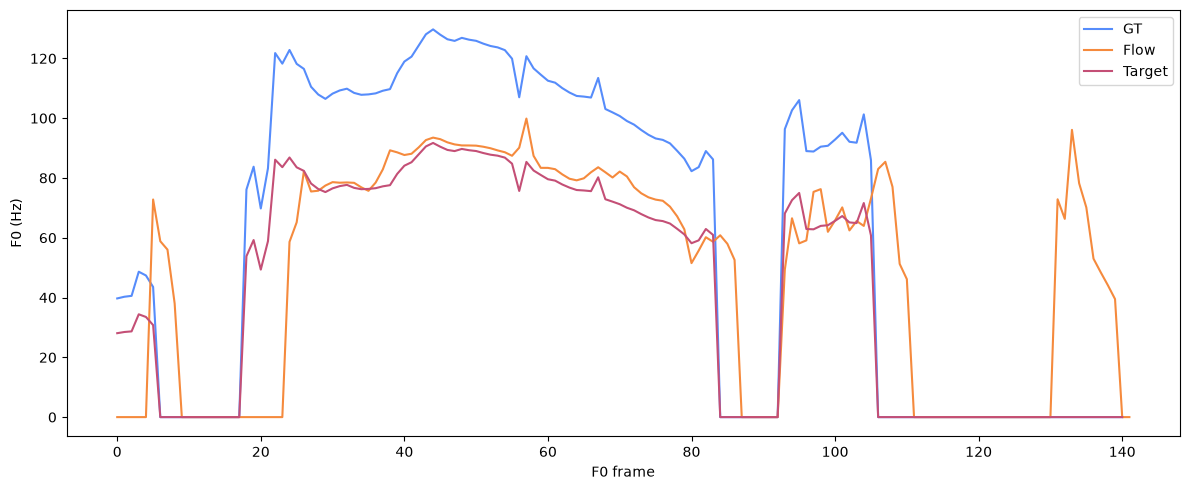

In [15]:
# Compute WORLD F0 from the raw edited audio for the final comparison.
# Uniform playback scaling does not alter F0, but using the raw signal keeps
# analysis separate from display normalization.
flow_f0 = get_f0(flow_audio_raw)

plt.figure(figsize=(12, 5))
plt.plot(f0_np, label="GT")
plt.plot(flow_f0, label="Flow")
plt.plot(target_f0, label="Target")
plt.xlabel("F0 frame")
plt.ylabel("F0 (Hz)")
plt.legend()
plt.tight_layout()
plt.show()


## Save audio outputs

In [16]:
# ============================================================
# Save edited outputs
# ============================================================

fast_audio_path = EDIT_OUTPUT_DIR / "edited_pitch_fast.wav"
flow_audio_path = EDIT_OUTPUT_DIR / "edited_pitch_flow.wav"
stereo_audio_path = EDIT_OUTPUT_DIR / "original_left_edited_right.wav"

# fast_audio and flow_audio have already been sanitized, uniformly limited,
# and hard-clipped to a valid floating-point audio range. stereo_comparison
# uses one shared gain for both channels.
torchaudio.save(
    str(fast_audio_path),
    torch.from_numpy(fast_audio).unsqueeze(0),
    SAMPLE_RATE,
)

torchaudio.save(
    str(flow_audio_path),
    torch.from_numpy(flow_audio).unsqueeze(0),
    SAMPLE_RATE,
)

torchaudio.save(
    str(stereo_audio_path),
    torch.from_numpy(stereo_comparison),
    SAMPLE_RATE,
)

print("Saved:", fast_audio_path)
print("Saved:", flow_audio_path)
print("Saved:", stereo_audio_path)


Saved: data/f0_edits/edited_pitch_fast.wav
Saved: data/f0_edits/edited_pitch_flow.wav
Saved: data/f0_edits/original_left_edited_right.wav


/home/bennie/PycharmProjects/PitchFlower/.venv/lib/python3.13/site-packages/torchaudio/_backend/utils.py:337: UserWarning: In 2.9, this function's implementation will be changed to use torchaudio.save_with_torchcodec` under the hood. Some parameters like format, encoding, bits_per_sample, buffer_size, and ``backend`` will be ignored. We recommend that you port your code to rely directly on TorchCodec's encoder instead: https://docs.pytorch.org/torchcodec/stable/generated/torchcodec.encoders.AudioEncoder
  warnings.warn(


## Re-editing loop

For repeated experiments you only need to:

1. Move/add/delete points in the interactive ratio editor.
2. Re-run **Freeze the current edit for synthesis**.
3. Re-run one or both synthesis cells.
4. Re-run the audio comparison and F0 comparison cells.
5. Save the point group when you have a contour you want to keep.

You do **not** need to re-run model loading, WORLD extraction, or `synth.analyze_audios(...)` unless you change the source audio.